Dataset Shape: (670, 10)

Coherence Scores:
 Number of Topics  Coherence Score
                2         0.380005
                3         0.351093
                4         0.345770
                5         0.375444
                6         0.334223
                7         0.389373
                8         0.430675

Best Number of Topics: 8
Best Coherence Score: 0.4307


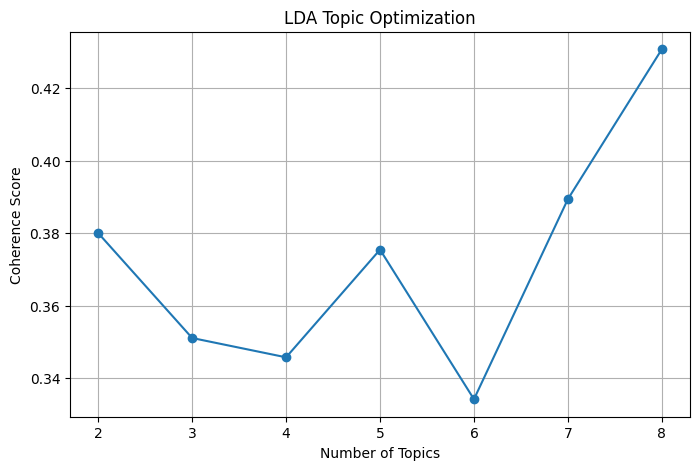


Topics and Important Words:
Topic 1 : fabric, feels, premium, soft, cheap, nice, photos, stylish, comfortable, quality
Topic 2 : looks, purchase, happy, nice, better, photos, expected, decent, fabric, cheap
Topic 3 : nice, product, quick, delivery, absolutely, love, cheap, fabric, feels, photos
Topic 4 : value, money, got, compliments, exchange, size, small, runs, cheap, nice
Topic 5 : rupee, worth, quality, price, average, okay, special, slightly, different, picture
Topic 6 : fit, loose, little, cheap, nice, photos, comfortable, stylish, fabric, quality
Topic 7 : quality, fit, good, nice, comfortable, stylish, great, perfect, fine, use
Topic 8 : color, shown, good, fabric, wash, faded, photos, cheap, nice, stylish


In [ ]:


import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel
import pyLDAvis
import pyLDAvis.lda_model


df = pd.read_csv("../dataset/womens_clothing_analysis.csv")
df = df.dropna(subset=["Review"])

reviews = df["Review"].astype(str)

print("Dataset Shape:", df.shape)


def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    return text

cleaned_reviews = reviews.apply(clean_text)

tfidf = TfidfVectorizer(
    stop_words="english",
    max_df=0.95,
    min_df=2,
    max_features=2000
)

tfidf_matrix = tfidf.fit_transform(cleaned_reviews)

selected_words = set(tfidf.get_feature_names_out())

tokenized_reviews = [
    [word for word in review.split() if word in selected_words]
    for review in cleaned_reviews
]


valid_reviews = [
    tokens for tokens in tokenized_reviews if tokens
]

dictionary = Dictionary(valid_reviews)

count_vectorizer = CountVectorizer(
    vocabulary=dictionary.token2id
)
count_matrix = count_vectorizer.fit_transform(
    [" ".join(tokens) for tokens in valid_reviews]
)

topic_numbers = [2, 3, 4, 5, 6, 7, 8]
coherence_scores = []
lda_models = []

for n_topics in topic_numbers:
    lda = LatentDirichletAllocation(
        n_components=n_topics,
        random_state=42,
        max_iter=10,
        learning_method="batch"
    )

    lda.fit(count_matrix)
    lda_models.append(lda)

    topics = []

    for topic in lda.components_:
        top_words = [
            count_vectorizer.get_feature_names_out()[i]
            for i in topic.argsort()[-10:][::-1]
        ]
        topics.append(top_words)

    coherence_model = CoherenceModel(
        topics=topics,
        texts=valid_reviews,
        dictionary=dictionary,
        coherence="c_v"
    )

    coherence_scores.append(coherence_model.get_coherence())


score_df = pd.DataFrame({
    "Number of Topics": topic_numbers,
    "Coherence Score": coherence_scores
})

print("\nCoherence Scores:")
print(score_df.to_string(index=False))

best_index = np.argmax(coherence_scores)
best_topics = topic_numbers[best_index]
best_lda = lda_models[best_index]

print("\nBest Number of Topics:", best_topics)
print("Best Coherence Score:", round(coherence_scores[best_index], 4))

plt.figure(figsize=(8, 5))
plt.plot(topic_numbers, coherence_scores, marker="o")
plt.xlabel("Number of Topics")
plt.ylabel("Coherence Score")
plt.title("LDA Topic Optimization")
plt.xticks(topic_numbers)
plt.grid(True)
plt.show()


feature_names = count_vectorizer.get_feature_names_out()

print("\nTopics and Important Words:")

for i, topic in enumerate(best_lda.components_):
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [feature_names[j] for j in top_indices]

    print("Topic", i + 1, ":", ", ".join(top_words))

panel = pyLDAvis.lda_model.prepare(
    best_lda,
    count_matrix,
    count_vectorizer,
    mds="pcoa"
)

pyLDAvis.display(panel)
